In [2]:
import pandas as pd
import numpy as np

import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error



import matplotlib.pyplot as subplots
import missingno as msno



# from sklearn.model_selection import train_test_split we would've used
# this if we automated our data seperation

In [3]:
data = pd.read_csv('./TIA-WEATHER-DATA-2015-01-01-TO-2025-06-30.csv')
data.columns

Index(['datetime', 'tempmax', 'tempmin', 'temp', 'dew', 'humidity',
       'precipprob', 'precipcover', 'preciptype', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility',
       'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'sunrise',
       'sunset', 'precipitation'],
      dtype='str')

In [4]:
data[0:10]

,datetime,tempmax,tempmin,temp,dew,humidity,precipprob,precipcover,preciptype,windgust,...,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,severerisk,sunrise,sunset,precipitation
0,2015-01-01,60.7,39.1,50.0,41.7,74.7,100,4.17,rain,11.2,...,1020.4,79.1,2.4,96.6,8.3,4,NaN,2015-01-01T06:54:15,2015-01-01T17:19:31,0.8
1,2015-01-02,71.0,49.9,54.9,48.4,80.1,100,20.83,rain,19.9,...,1022.2,93.3,2.9,40.4,3.3,2,NaN,2015-01-02T06:54:31,2015-01-02T17:20:12,0.0
2,2015-01-03,67.7,48.1,54.8,50.5,86.3,100,8.33,rain,15.4,...,1021.0,90.3,2.8,58.6,5.0,4,NaN,2015-01-03T06:54:46,2015-01-03T17:20:54,0.5
3,2015-01-04,69.9,48.1,54.5,49.6,85.5,100,4.17,rain,17.0,...,1018.1,67.1,2.7,118.0,10.3,6,NaN,2015-01-04T06:54:58,2015-01-04T17:21:37,0.5
4,2015-01-05,64.3,42.7,51.3,45.7,83.2,0,0.00,NaN,16.3,...,1013.9,41.6,3.9,139.2,12.0,6,NaN,2015-01-05T06:55:10,2015-01-05T17:22:20,0.0
5,2015-01-06,62.5,46.3,52.2,45.0,78.0,0,0.00,NaN,16.1,...,1016.4,62.5,3.7,98.8,8.5,5,NaN,2015-01-06T06:55:20,2015-01-06T17:23:04,0.0
6,2015-01-07,60.7,43.4,50.3,43.1,77.8,0,0.00,NaN,15.7,...,1017.1,65.7,3.4,102.8,8.9,5,NaN,2015-01-07T06:55:28,2015-01-07T17:23:49,0.0
7,2015-01-08,71.7,39.1,49.3,41.5,76.4,100,4.17,rain,15.7,...,1018.9,50.1,3.9,114.1,9.7,5,NaN,2015-01-08T06:55:35,2015-01-08T17:24:34,0.0
8,2015-01-09,64.3,39.1,48.4,38.7,72.8,0,0.00,NaN,15.4,...,1020.3,24.0,3.8,173.6,14.8,7,NaN,2015-01-09T06:55:40,2015-01-09T17:25:20,0.0
9,2015-01-10,67.9,35.5,47.9,35.7,68.2,0,0.00,NaN,12.1,...,1018.8,22.9,3.9,190.1,16.2,7,NaN,2015-01-10T06:55:44,2015-01-10T17:26:06,0.0


In [5]:
data.columns

Index(['datetime', 'tempmax', 'tempmin', 'temp', 'dew', 'humidity',
       'precipprob', 'precipcover', 'preciptype', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility',
       'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'sunrise',
       'sunset', 'precipitation'],
      dtype='str')

In [6]:

columns_to_keep = ['datetime', 'tempmax', 'tempmin', 'temp', 'dew', 'humidity',
       'precipprob', 'precipcover', 'windgust', 'windspeed',
       'winddir', 'sealevelpressure', 'cloudcover', 'visibility',
       'solarradiation', 'solarenergy', 'uvindex', 'sunrise',
       'sunset', 'precipitation']

data = data[columns_to_keep]

data[:10]


,datetime,tempmax,tempmin,temp,dew,humidity,precipprob,precipcover,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,sunrise,sunset,precipitation
0,2015-01-01,60.7,39.1,50.0,41.7,74.7,100,4.17,11.2,5.8,166.0,1020.4,79.1,2.4,96.6,8.3,4,2015-01-01T06:54:15,2015-01-01T17:19:31,0.8
1,2015-01-02,71.0,49.9,54.9,48.4,80.1,100,20.83,19.9,9.2,26.0,1022.2,93.3,2.9,40.4,3.3,2,2015-01-02T06:54:31,2015-01-02T17:20:12,0.0
2,2015-01-03,67.7,48.1,54.8,50.5,86.3,100,8.33,15.4,15.7,304.8,1021.0,90.3,2.8,58.6,5.0,4,2015-01-03T06:54:46,2015-01-03T17:20:54,0.5
3,2015-01-04,69.9,48.1,54.5,49.6,85.5,100,4.17,17.0,9.2,252.4,1018.1,67.1,2.7,118.0,10.3,6,2015-01-04T06:54:58,2015-01-04T17:21:37,0.5
4,2015-01-05,64.3,42.7,51.3,45.7,83.2,0,0.00,16.3,10.3,213.3,1013.9,41.6,3.9,139.2,12.0,6,2015-01-05T06:55:10,2015-01-05T17:22:20,0.0
5,2015-01-06,62.5,46.3,52.2,45.0,78.0,0,0.00,16.1,10.3,243.1,1016.4,62.5,3.7,98.8,8.5,5,2015-01-06T06:55:20,2015-01-06T17:23:04,0.0
6,2015-01-07,60.7,43.4,50.3,43.1,77.8,0,0.00,15.7,10.3,233.9,1017.1,65.7,3.4,102.8,8.9,5,2015-01-07T06:55:28,2015-01-07T17:23:49,0.0
7,2015-01-08,71.7,39.1,49.3,41.5,76.4,100,4.17,15.7,6.9,203.0,1018.9,50.1,3.9,114.1,9.7,5,2015-01-08T06:55:35,2015-01-08T17:24:34,0.0
8,2015-01-09,64.3,39.1,48.4,38.7,72.8,0,0.00,15.4,9.2,58.0,1020.3,24.0,3.8,173.6,14.8,7,2015-01-09T06:55:40,2015-01-09T17:25:20,0.0
9,2015-01-10,67.9,35.5,47.9,35.7,68.2,0,0.00,12.1,8.1,280.9,1018.8,22.9,3.9,190.1,16.2,7,2015-01-10T06:55:44,2015-01-10T17:26:06,0.0


In [7]:
data.dtypes

datetime                str
tempmax             float64
tempmin             float64
temp                float64
dew                 float64
humidity            float64
precipprob            int64
precipcover         float64
windgust            float64
windspeed           float64
winddir             float64
sealevelpressure    float64
cloudcover          float64
visibility          float64
solarradiation      float64
solarenergy         float64
uvindex               int64
sunrise                 str
sunset                  str
precipitation       float64
dtype: object

In [8]:
# STEP 1: Explicitly convert the text strings into true datetimes first
data['sunrise'] = pd.to_datetime(data['sunrise'])
data['sunset'] = pd.to_datetime(data['sunset'])

# STEP 2: Now convert the true datetimes into unix integers safely
data['sunrise'] = data['sunrise'].astype('int64') // 10**9
data['sunset'] = data['sunset'].astype('int64') // 10**9

data['datetime'] = pd.to_datetime(data['datetime'])


In [9]:
data = data.set_index('datetime')

In [10]:
data[:10]

,tempmax,tempmin,temp,dew,humidity,precipprob,precipcover,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,sunrise,sunset,precipitation
datetime,,,,,,,,,,,,,,,,,,,
2015-01-01,60.7,39.1,50.0,41.7,74.7,100,4.17,11.2,5.8,166.0,1020.4,79.1,2.4,96.6,8.3,4,1420095,1420132,0.8
2015-01-02,71.0,49.9,54.9,48.4,80.1,100,20.83,19.9,9.2,26.0,1022.2,93.3,2.9,40.4,3.3,2,1420181,1420219,0.0
2015-01-03,67.7,48.1,54.8,50.5,86.3,100,8.33,15.4,15.7,304.8,1021.0,90.3,2.8,58.6,5.0,4,1420268,1420305,0.5
2015-01-04,69.9,48.1,54.5,49.6,85.5,100,4.17,17.0,9.2,252.4,1018.1,67.1,2.7,118.0,10.3,6,1420354,1420392,0.5
2015-01-05,64.3,42.7,51.3,45.7,83.2,0,0.00,16.3,10.3,213.3,1013.9,41.6,3.9,139.2,12.0,6,1420440,1420478,0.0
2015-01-06,62.5,46.3,52.2,45.0,78.0,0,0.00,16.1,10.3,243.1,1016.4,62.5,3.7,98.8,8.5,5,1420527,1420564,0.0
2015-01-07,60.7,43.4,50.3,43.1,77.8,0,0.00,15.7,10.3,233.9,1017.1,65.7,3.4,102.8,8.9,5,1420613,1420651,0.0
2015-01-08,71.7,39.1,49.3,41.5,76.4,100,4.17,15.7,6.9,203.0,1018.9,50.1,3.9,114.1,9.7,5,1420700,1420737,0.0
2015-01-09,64.3,39.1,48.4,38.7,72.8,0,0.00,15.4,9.2,58.0,1020.3,24.0,3.8,173.6,14.8,7,1420786,1420824,0.0


In [11]:
import pandas as pd

stats = data.describe()

print(stats)

           tempmax      tempmin         temp          dew     humidity  \
count  3468.000000  3468.000000  3468.000000  3468.000000  3468.000000   
mean     76.085294    57.193829    65.385265    56.108333    75.141984   
std       7.789576    10.985584     9.146426    11.408154    11.479143   
min      48.100000    32.100000    44.000000    29.000000    25.200000   
25%      69.700000    48.100000    57.175000    45.700000    69.400000   
50%      76.900000    58.900000    67.600000    56.300000    76.200000   
75%      82.300000    67.900000    73.600000    67.925000    83.300000   
max     102.100000    75.100000    81.000000    74.300000   100.000000   

        precipprob  precipcover     windgust    windspeed      winddir  \
count  3468.000000  3468.000000  3468.000000  3468.000000  3468.000000   
mean     38.437140     2.515107    17.471943    11.262197   212.394319   
std      48.651647     4.780395     4.169347     5.879100    57.765426   
min       0.000000     0.000000     4

In [12]:
import pandas as pd

# 1. Generate your full timeline
expected_dates = pd.date_range(start=data.index.min(), end=data.index.max(), freq='D')

# 2. Extract all missing dates
missing_dates = expected_dates.difference(data.index)

# 3. Print the exact start and end boundaries of the gap
if not missing_dates.empty:
    print(f"Data is missing FROM: {missing_dates.min().strftime('%Y-%m-%d')}")
    print(f"Data is missing UNTIL: {missing_dates.max().strftime('%Y-%m-%d')}")
    print(f"Total duration of the gap: {len(missing_dates)} days")
else:
    print("No missing data entries found!")


Data is missing FROM: 2015-07-01
Data is missing UNTIL: 2016-06-30
Total duration of the gap: 366 days


In [13]:
data.isnull().sum()

tempmax             0
tempmin             0
temp                0
dew                 0
humidity            0
precipprob          0
precipcover         0
windgust            0
windspeed           0
winddir             0
sealevelpressure    0
cloudcover          0
visibility          0
solarradiation      0
solarenergy         0
uvindex             0
sunrise             0
sunset              0
precipitation       0
dtype: int64

In [14]:
# Drop rows where lag features couldn't be calculated
data = data.dropna()

# Double check that your missing value counts are all 0
print(data.isna().sum())


tempmax             0
tempmin             0
temp                0
dew                 0
humidity            0
precipprob          0
precipcover         0
windgust            0
windspeed           0
winddir             0
sealevelpressure    0
cloudcover          0
visibility          0
solarradiation      0
solarenergy         0
uvindex             0
sunrise             0
sunset              0
precipitation       0
dtype: int64


In [15]:
data[180:365]

,tempmax,tempmin,temp,dew,humidity,precipprob,precipcover,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,sunrise,sunset,precipitation
datetime,,,,,,,,,,,,,,,,,,,
2015-06-30,92.0,68.6,76.5,69.5,80.2,100,12.50,15.7,10.3,271.7,1011.9,73.9,4.0,210.6,18.2,8,1435641,1435690,0.0
2016-07-01,71.5,67.9,69.9,68.9,96.8,100,4.17,21.9,9.2,78.4,1009.1,97.0,3.3,53.0,4.6,3,1467349,1467399,53.1
2016-07-02,80.5,67.9,71.0,69.0,93.9,100,8.33,20.8,9.2,172.1,1009.8,91.0,4.2,105.7,8.9,4,1467436,1467486,13.7
2016-07-03,84.1,69.7,73.8,69.8,88.4,100,4.17,18.3,12.8,216.1,1007.7,86.3,4.4,145.6,12.5,6,1467522,1467572,2.0
2016-07-04,80.5,69.7,74.7,69.4,84.5,100,4.17,15.4,5.8,177.7,1006.3,85.3,4.7,151.3,13.0,6,1467609,1467658,16.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-27,66.1,40.9,52.2,42.9,74.0,0,0.00,12.8,9.2,233.5,1020.2,27.1,2.6,171.7,14.9,6,1482821,1482858,0.0
2016-12-28,64.3,40.9,51.3,44.1,79.1,0,0.00,13.6,10.3,183.7,1019.4,30.2,2.8,170.7,14.6,7,1482907,1482945,0.0
2016-12-29,64.3,40.9,51.0,43.9,79.4,0,0.00,13.0,5.8,147.2,1021.1,31.3,2.1,163.8,14.1,7,1482994,1483031,0.0


In [16]:
expected_dates = pd.date_range(start=data.index.min(), end=data.index.max())
missing_dates = expected_dates.difference(data.index)
missing_dates

print(missing_dates);

DatetimeIndex(['2015-07-01', '2015-07-02', '2015-07-03', '2015-07-04',
               '2015-07-05', '2015-07-06', '2015-07-07', '2015-07-08',
               '2015-07-09', '2015-07-10',
               ...
               '2016-06-21', '2016-06-22', '2016-06-23', '2016-06-24',
               '2016-06-25', '2016-06-26', '2016-06-27', '2016-06-28',
               '2016-06-29', '2016-06-30'],
              dtype='datetime64[us]', length=366, freq='D')


In [17]:


# 1. Generate the perfect continuous datetime timeline
ideal_index = pd.date_range(start=data.index.min(), end=data.index.max(), freq='D')

# 2. Reindex data to force missing timestamps into true empty rows
reindexed_data = data.reindex(ideal_index)

# 3. Target the reindexed index to look for missing entries
is_null_series = reindexed_data.index.to_series().isnull()

# 4. Group and calculate the size of consecutive true/false missing blocks
block_groups = (is_null_series != is_null_series.shift()).cumsum()
blocks = is_null_series.groupby(block_groups).size()
missing_lengths = blocks[is_null_series.groupby(block_groups).first()]

# 5. Output the final summary table
print("Frequency of missing datetime block sizes:")
print(missing_lengths.value_counts())


Frequency of missing datetime block sizes:
Series([], Name: count, dtype: int64)


In [18]:
import pandas as pd

# 1. Generate your full timeline
expected_dates = pd.date_range(start=data.index.min(), end=data.index.max(), freq='D')

# 2. Extract all missing dates
missing_dates = expected_dates.difference(data.index)

# 3. Print the exact start and end boundaries of the gap
if not missing_dates.empty:
    print(f"Data is missing FROM: {missing_dates.min().strftime('%Y-%m-%d')}")
    print(f"Data is missing UNTIL: {missing_dates.max().strftime('%Y-%m-%d')}")
    print(f"Total duration of the gap: {len(missing_dates)} days")
else:
    print("No missing data entries found!")


data[0:-1]

Data is missing FROM: 2015-07-01
Data is missing UNTIL: 2016-06-30
Total duration of the gap: 366 days


,tempmax,tempmin,temp,dew,humidity,precipprob,precipcover,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,sunrise,sunset,precipitation
datetime,,,,,,,,,,,,,,,,,,,
2015-01-01,60.7,39.1,50.0,41.7,74.7,100,4.17,11.2,5.8,166.0,1020.4,79.1,2.4,96.6,8.3,4,1420095,1420132,0.8000
2015-01-02,71.0,49.9,54.9,48.4,80.1,100,20.83,19.9,9.2,26.0,1022.2,93.3,2.9,40.4,3.3,2,1420181,1420219,0.0000
2015-01-03,67.7,48.1,54.8,50.5,86.3,100,8.33,15.4,15.7,304.8,1021.0,90.3,2.8,58.6,5.0,4,1420268,1420305,0.5000
2015-01-04,69.9,48.1,54.5,49.6,85.5,100,4.17,17.0,9.2,252.4,1018.1,67.1,2.7,118.0,10.3,6,1420354,1420392,0.5000
2015-01-05,64.3,42.7,51.3,45.7,83.2,0,0.00,16.3,10.3,213.3,1013.9,41.6,3.9,139.2,12.0,6,1420440,1420478,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-25,82.3,69.7,75.5,70.6,86.1,100,4.17,4.7,13.9,254.5,1010.5,81.7,4.4,220.5,19.0,7,1750828,1750878,8.9000
2025-06-26,84.1,71.5,76.7,71.6,85.9,100,8.33,5.6,11.4,220.1,1011.7,75.9,4.6,301.5,26.1,9,1750914,1750964,9.9000
2025-06-27,82.3,69.7,76.7,71.1,84.0,100,54.17,5.8,12.8,237.0,1010.3,80.1,5.1,266.0,23.1,9,1751001,1751050,18.8000


In [19]:
#Lagging feature

data['precip_lag1'] = data['precipitation'].shift(1)
data['precip_lag3'] = data['precipitation'].shift(3)
data['precip_lag7'] = data['precipitation'].shift(7)


data['humidity_lag1'] = data['humidity'].shift(1)
data['cloudcover_lag1'] = data['cloudcover'].shift(1)

In [20]:
#Rolling Statisitics

data['precip_mean_7d'] = data['precipitation'].rolling(7).mean()
data['precip_mean_30d'] = data['precipitation'].rolling(30).mean()

data['humidity_mean_7d'] = data['humidity'].rolling(7).mean()
data['temp_mean_7d'] = data['temp'].rolling(7).mean()

In [21]:
#Date features

data['month_sin'] = np.sin(2*np.pi*data.index.month/12)
data['month_cos'] = np.cos(2*np.pi*data.index.month/12)

data['day_sin'] = np.sin(2*np.pi*data.index.dayofyear/365)
data['day_cos'] = np.cos(2*np.pi*data.index.dayofyear/365)


In [22]:
data['dew_gap'] = data['temp'] - data['dew']

In [23]:
data['temp_range'] = data['tempmax'] - data['tempmin']

In [24]:
data['pressure_change_1d'] = data['sealevelpressure'].diff()
data['pressure_change_3d'] = data['sealevelpressure'].diff(3)

In [25]:
import numpy as np

data['wind_u'] = data['windspeed'] * np.cos(np.radians(data['winddir']))
data['wind_v'] = data['windspeed'] * np.sin(np.radians(data['winddir']))

In [26]:
data['cloud_change'] = data['cloudcover'].diff()
data['cloud_mean_3d'] = data['cloudcover'].rolling(3).mean()

In [27]:
data['humidity_change'] = data['humidity'].diff()

In [28]:
data['humid_pressure'] = (
    data['humidity'] / data['sealevelpressure']
)

In [29]:
data['day_length'] = (
    pd.to_datetime(data['sunset']) -
    pd.to_datetime(data['sunrise'])
).dt.total_seconds()/3600

In [30]:
data.columns

Index(['tempmax', 'tempmin', 'temp', 'dew', 'humidity', 'precipprob',
       'precipcover', 'windgust', 'windspeed', 'winddir', 'sealevelpressure',
       'cloudcover', 'visibility', 'solarradiation', 'solarenergy', 'uvindex',
       'sunrise', 'sunset', 'precipitation', 'precip_lag1', 'precip_lag3',
       'precip_lag7', 'humidity_lag1', 'cloudcover_lag1', 'precip_mean_7d',
       'precip_mean_30d', 'humidity_mean_7d', 'temp_mean_7d', 'month_sin',
       'month_cos', 'day_sin', 'day_cos', 'dew_gap', 'temp_range',
       'pressure_change_1d', 'pressure_change_3d', 'wind_u', 'wind_v',
       'cloud_change', 'cloud_mean_3d', 'humidity_change', 'humid_pressure',
       'day_length'],
      dtype='str')

<Axes: >

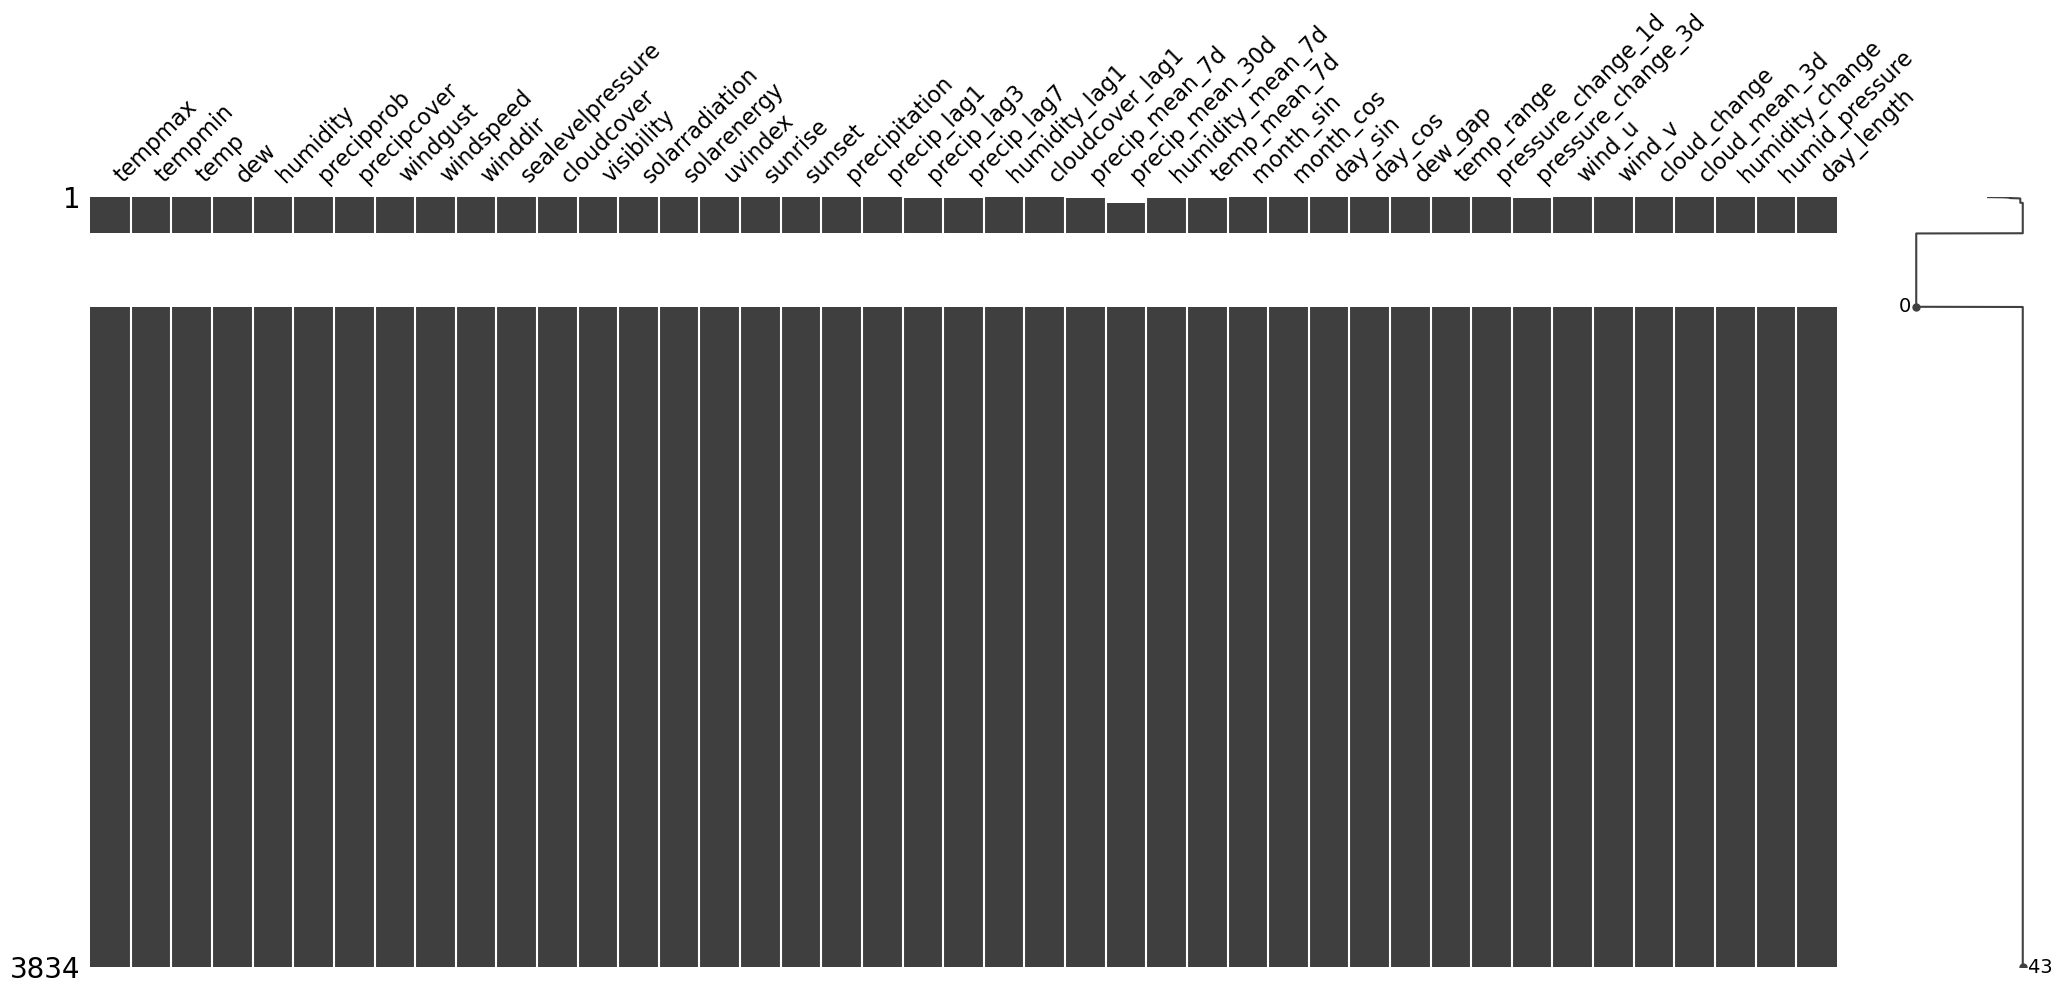

In [31]:
import missingno as msno
import missingno as msno

# Make sure you are plotting the reindexed dataframe to see the timeline gap
msno.matrix(data.reindex(pd.date_range(start=data.index.min(), end=data.index.max(), freq='D')))


In [32]:
data.describe()

,tempmax,tempmin,temp,dew,humidity,precipprob,precipcover,windgust,windspeed,winddir,...,temp_range,pressure_change_1d,pressure_change_3d,wind_u,wind_v,cloud_change,cloud_mean_3d,humidity_change,humid_pressure,day_length
count,3468.000000,3468.000000,3468.000000,3468.000000,3468.000000,3468.000000,3468.000000,3468.000000,3468.000000,3468.000000,...,3468.000000,3467.000000,3465.00000,3468.000000,3468.000000,3467.000000,3466.000000,3467.000000,3468.000000,3.468000e+03
mean,76.085294,57.193829,65.385265,56.108333,75.141984,38.437140,2.515107,17.471943,11.262197,212.394319,...,18.891465,-0.004586,-0.01241,-5.403173,-4.486898,0.004067,47.180785,0.004615,0.074018,1.216399e-11
std,7.789576,10.985584,9.146426,11.408154,11.479143,48.651647,4.780395,4.169347,5.879100,57.765426,...,6.236340,1.513278,2.69444,7.305798,7.663030,12.205737,22.764535,5.336146,0.011432,1.212528e-12
min,48.100000,32.100000,44.000000,29.000000,25.200000,0.000000,0.000000,4.700000,3.400000,1.000000,...,1.800000,-6.100000,-10.00000,-142.711028,-97.480876,-52.500000,20.833333,-20.800000,0.024955,1.027778e-11
25%,69.700000,48.100000,57.175000,45.700000,69.400000,0.000000,0.000000,15.000000,9.200000,184.175000,...,14.400000,-1.000000,-1.70000,-9.600980,-9.164051,-4.150000,26.500000,-3.100000,0.068161,1.111111e-11
50%,76.900000,58.900000,67.600000,56.300000,76.200000,0.000000,0.000000,16.600000,10.300000,214.900000,...,19.600000,0.000000,0.00000,-6.199895,-6.095547,0.000000,37.883333,-0.100000,0.074882,1.222222e-11
75%,82.300000,67.900000,73.600000,67.925000,83.300000,100.000000,4.170000,19.000000,12.800000,252.225000,...,23.400000,1.000000,1.70000,-1.644380,-0.771670,3.800000,68.866667,2.800000,0.082207,1.333333e-11
max,102.100000,75.100000,81.000000,74.300000,100.000000,100.000000,62.500000,53.000000,165.800000,356.800000,...,41.400000,6.500000,11.40000,35.488254,76.250019,52.000000,93.333333,35.300000,0.099157,1.388889e-11


In [33]:
predictor_columns = ['tempmax', 'tempmin', 'temp', 'dew', 'humidity', 
       'windgust', 'windspeed', 'winddir', 'sealevelpressure',
       'cloudcover', 'visibility', 'solarradiation', 'solarenergy', 'uvindex',
       'sunrise', 'sunset', 'precip_lag1', 'precip_lag3',
       'precip_lag7', 'humidity_lag1', 'cloudcover_lag1', 'precip_mean_7d',
       'precip_mean_30d', 'humidity_mean_7d', 'temp_mean_7d', 'month_sin',
       'month_cos', 'day_sin', 'day_cos']

target =  'precipitation'

In [34]:
# Keep the DataFrame sorted chronologically
data = data.sort_index()

X = data[predictor_columns]
y = data[target]

# Train on the older, historical data (approx. 9 years)
X_train = X.loc['2015-01-01':'2024-06-30']
y_train = y.loc['2015-01-01':'2024-06-30']

# Test on the most recent data (1 Year)
X_test = X.loc['2024-07-01':'2025-06-29']
y_test = y.loc['2024-07-01':'2025-06-29']


In [35]:
model =xgb.XGBRegressor(n_estimators=500,learning_rate = 0.01)

In [36]:
model.fit(X_train,y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [37]:
predictions = model.predict(X_test)


In [38]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 2. Run your evaluation calculations
rmse = np.sqrt(mean_squared_error(y_test, predictions))
mae = mean_absolute_error(y_test, predictions)

# 3. Print the results to your screen
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

Root Mean Squared Error (RMSE): 10.5301
Mean Absolute Error (MAE): 4.5014


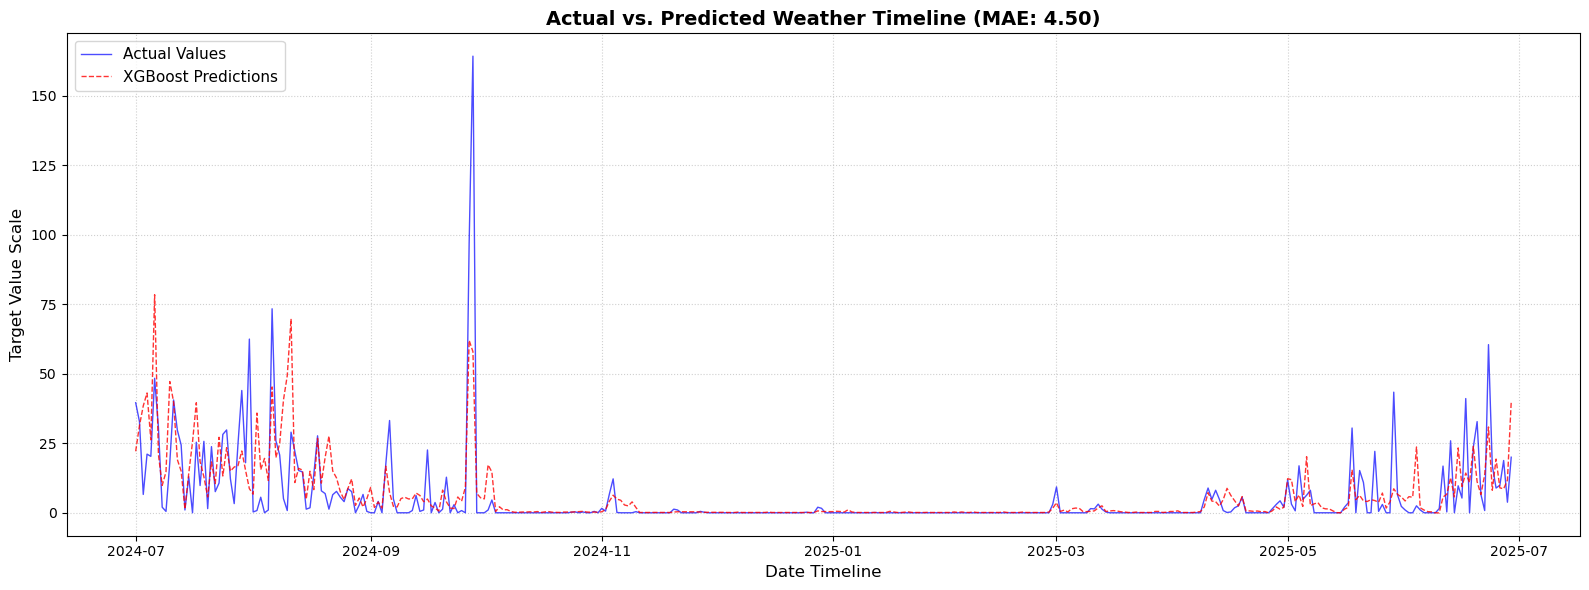

In [39]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Set up the plotting canvas size (Width=12 inches, Height=6 inches)
plt.figure(figsize=(16, 6))

# 2. Plot the true actual values (Blue line)
# We use y_test.index as the X-axis timeline
plt.plot(y_test.index, y_test.values, label='Actual Values', color='blue', alpha=0.7, linewidth=1)

# 3. Plot the model's predictions (Red dashed line)
plt.plot(y_test.index, predictions, label='XGBoost Predictions', color='red', linestyle='--', alpha=0.8, linewidth=1)

# 4. Add clear descriptions and labels
plt.title(f'Actual vs. Predicted Weather Timeline (MAE: {mae:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Date Timeline', fontsize=12)
plt.ylabel('Target Value Scale', fontsize=12)

# 5. Add a legend so we know which line is which
plt.legend(fontsize=11, loc='upper left')

# 6. Clean up the layout and display the plot
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


In [40]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, mean_absolute_error

# Convert arrays into a single, clean Pandas DataFrame for easy filtering
eval_data = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': predictions
}, index=y_test.index)

# Define a tiny threshold because regression models rarely predict exactly 0.0000
# If the prediction is greater than 0.1, we classify it as a "Predicted Rain Day"
threshold = 0.1

eval_data['Actual_Rain'] = eval_data['Actual'] > 0.0
eval_data['Predicted_Rain'] = eval_data['Predicted'] > threshold

# ---------------------------------------------------------------------------
# QUESTION 1: "When the model said it was going to rain, did it?" (Precision)
# ---------------------------------------------------------------------------
# Filter to look ONLY at days where the model predicted rain
predicted_rain_days = eval_data[eval_data['Predicted_Rain'] == True]

if len(predicted_rain_days) > 0:
    # Calculate how many of those predicted days actually had rain
    actually_rained_count = predicted_rain_days['Actual_Rain'].sum()
    precision = (actually_rained_count / len(predicted_rain_days)) * 100
else:
    precision = 0.0

# ---------------------------------------------------------------------------
# QUESTION 2: "When it did rain, how accurate was the amount?" (Conditional MAE)
# ---------------------------------------------------------------------------
# Filter to look ONLY at days where it actually rained in the real world
actual_rain_days = eval_data[eval_data['Actual_Rain'] == True]

if len(actual_rain_days) > 0:
    rain_amount_mae = mean_absolute_error(actual_rain_days['Actual'], actual_rain_days['Predicted'])
else:
    rain_amount_mae = 0.0

# ---------------------------------------------------------------------------
# PRINT THE LESSON RESULTS
# ---------------------------------------------------------------------------
print("=== QUESTION 1: RAIN DETECTION ACCURACY ===")
print(f"The model predicted rain on {len(predicted_rain_days)} days.")
print(f"Out of those days, it actually rained on {actually_rained_count} days.")
print(f"👉 Precision Score: {precision:.2f}% of the time the model said 'Rain', it was correct.")
print("\n" + "="*43)
print("=== QUESTION 2: RAIN AMOUNT ACCURACY ===")
print(f"There were {len(actual_rain_days)} actual rainy days in the test set.")
print(f"👉 Rainy Day MAE: On days it actually rained, the model missed the amount by an average of {rain_amount_mae:.2f} units.")


=== QUESTION 1: RAIN DETECTION ACCURACY ===
The model predicted rain on 291 days.
Out of those days, it actually rained on 153 days.
👉 Precision Score: 52.58% of the time the model said 'Rain', it was correct.

=== QUESTION 2: RAIN AMOUNT ACCURACY ===
There were 156 actual rainy days in the test set.
👉 Rainy Day MAE: On days it actually rained, the model missed the amount by an average of 8.99 units.


In [41]:
'''
If you are predicting smooth, continuous variables (Temperatures, Cloud Cover, Solar Energy) → Use RMSE.
If you are predicting spiky, zero-heavy variables (Precipitation / Rain) → Use MAE.
'''

'\nIf you are predicting smooth, continuous variables (Temperatures, Cloud Cover, Solar Energy) → Use RMSE.\nIf you are predicting spiky, zero-heavy variables (Precipitation / Rain) → Use MAE.\n'

In [42]:
data.describe

<bound method NDFrame.describe of             tempmax  tempmin  temp   dew  humidity  precipprob  precipcover  \
datetime                                                                      
2015-01-01     60.7     39.1  50.0  41.7      74.7         100         4.17   
2015-01-02     71.0     49.9  54.9  48.4      80.1         100        20.83   
2015-01-03     67.7     48.1  54.8  50.5      86.3         100         8.33   
2015-01-04     69.9     48.1  54.5  49.6      85.5         100         4.17   
2015-01-05     64.3     42.7  51.3  45.7      83.2           0         0.00   
...             ...      ...   ...   ...       ...         ...          ...   
2025-06-26     84.1     71.5  76.7  71.6      85.9         100         8.33   
2025-06-27     82.3     69.7  76.7  71.1      84.0         100        54.17   
2025-06-28     82.3     71.5  76.1  70.5      84.3         100        58.33   
2025-06-29     82.3     71.5  73.5  71.4      94.2         100        62.50   
2025-06-30     76.

In [43]:
eval_df = pd.DataFrame({
    'actual': y_test.values,
    'pred': predictions
}, index=y_test.index)

threshold = 0.1

eval_df['actual_rain'] = eval_df['actual'] > 0
eval_df['pred_rain'] = eval_df['pred'] > threshold
eval_df['correct'] = (
    eval_df['actual_rain'] == eval_df['pred_rain']
)

In [44]:
from sklearn.metrics import mean_absolute_error

def evaluate_window(df, window_days):
    results = []

    for i in range(len(df) - window_days + 1):
        window = df.iloc[i:i+window_days]

        accuracy = window['correct'].mean() * 100
        mae = mean_absolute_error(window['actual'], window['pred'])

        results.append({
            'start': window.index[0],
            'end': window.index[-1],
            'accuracy': accuracy,
            'mae': mae
        })

    return pd.DataFrame(results)

In [45]:
monthly_results = evaluate_window(eval_df, 30)

In [46]:
best_month_acc = monthly_results.loc[
    monthly_results['accuracy'].idxmax()
]

print("BEST 1-MONTH ACCURACY")
print(best_month_acc)

BEST 1-MONTH ACCURACY
start       2024-07-01 00:00:00
end         2024-07-30 00:00:00
accuracy              96.666667
mae                   11.717887
Name: 0, dtype: object


In [47]:
best_month_mae = monthly_results.loc[
    monthly_results['mae'].idxmin()
]

print("LOWEST 1-MONTH MAE")
print(best_month_mae)

LOWEST 1-MONTH MAE
start       2024-11-28 00:00:00
end         2024-12-27 00:00:00
accuracy              63.333333
mae                    0.118466
Name: 150, dtype: object


In [48]:
quarter_results = evaluate_window(eval_df, 90)

In [49]:
best_3m_acc = quarter_results.loc[
    quarter_results['accuracy'].idxmax()
]

print("BEST 3-MONTH ACCURACY")
print(best_3m_acc)

BEST 3-MONTH ACCURACY
start       2024-07-01 00:00:00
end         2024-09-28 00:00:00
accuracy              83.333333
mae                   11.530047
Name: 0, dtype: object


In [50]:
best_3m_mae = quarter_results.loc[
    quarter_results['mae'].idxmin()
]

print("LOWEST 3-MONTH MAE")
print(best_3m_mae)

LOWEST 3-MONTH MAE
start       2024-11-28 00:00:00
end         2025-02-25 00:00:00
accuracy                   60.0
mae                    0.186003
Name: 150, dtype: object


In [51]:
monthly_results['score'] = (
    monthly_results['accuracy'] - monthly_results['mae']*2
)

best_overall = monthly_results.loc[
    monthly_results['score'].idxmax()
]

print(best_overall)

start       2024-07-01 00:00:00
end         2024-07-30 00:00:00
accuracy              96.666667
mae                   11.717887
score                 73.230893
Name: 0, dtype: object


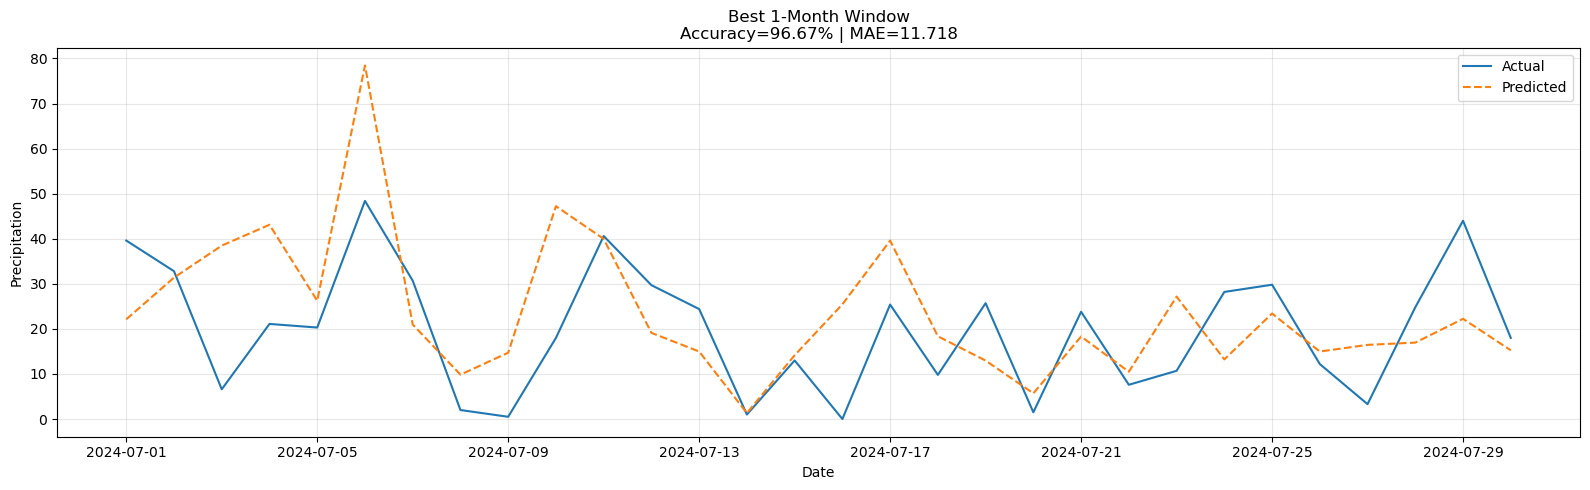

In [52]:
import matplotlib.pyplot as plt

month_start = best_month_acc['start']
month_end = best_month_acc['end']

best_month_data = eval_df.loc[month_start:month_end]

plt.figure(figsize=(16, 5))
plt.plot(
    best_month_data.index,
    best_month_data['actual'],
    label='Actual',
    linewidth=1.5
)

plt.plot(
    best_month_data.index,
    best_month_data['pred'],
    label='Predicted',
    linestyle='--',
    linewidth=1.5
)

plt.title(
    f"Best 1-Month Window\nAccuracy={best_month_acc['accuracy']:.2f}% | MAE={best_month_acc['mae']:.3f}"
)
plt.xlabel("Date")
plt.ylabel("Precipitation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

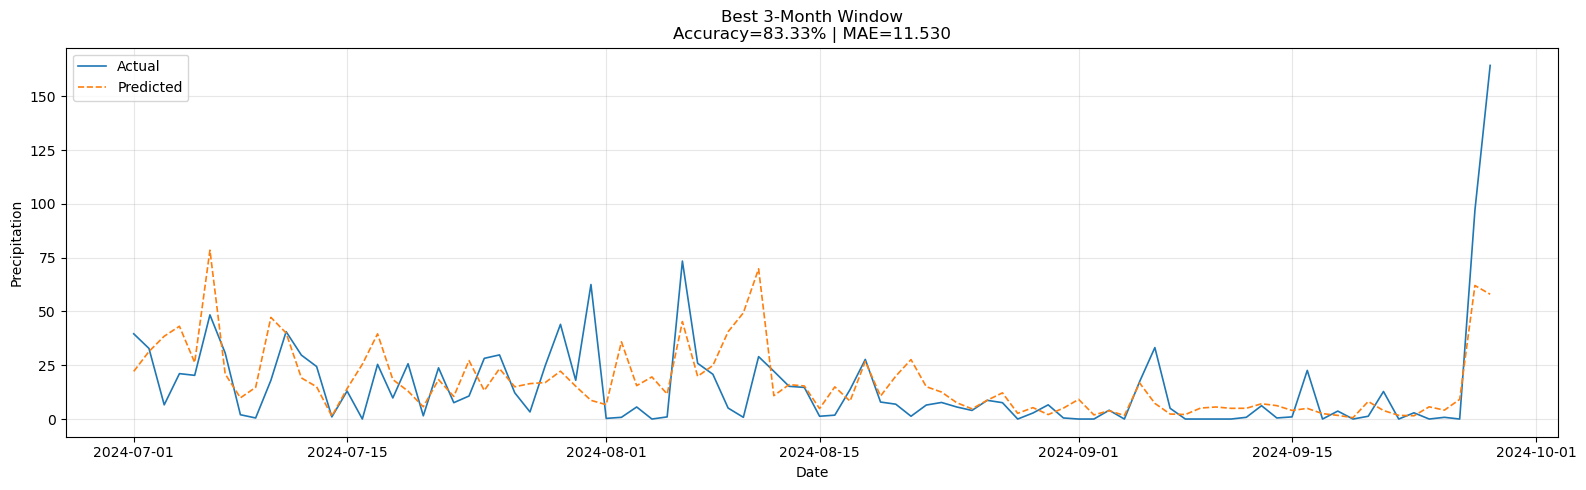

In [53]:
quarter_start = best_3m_acc['start']
quarter_end = best_3m_acc['end']

best_quarter_data = eval_df.loc[quarter_start:quarter_end]

plt.figure(figsize=(16, 5))
plt.plot(
    best_quarter_data.index,
    best_quarter_data['actual'],
    label='Actual',
    linewidth=1.2
)

plt.plot(
    best_quarter_data.index,
    best_quarter_data['pred'],
    label='Predicted',
    linestyle='--',
    linewidth=1.2
)

plt.title(
    f"Best 3-Month Window\nAccuracy={best_3m_acc['accuracy']:.2f}% | MAE={best_3m_acc['mae']:.3f}"
)
plt.xlabel("Date")
plt.ylabel("Precipitation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig( 'Image',dpi=1000, bbox_inches='tight')
plt.show()



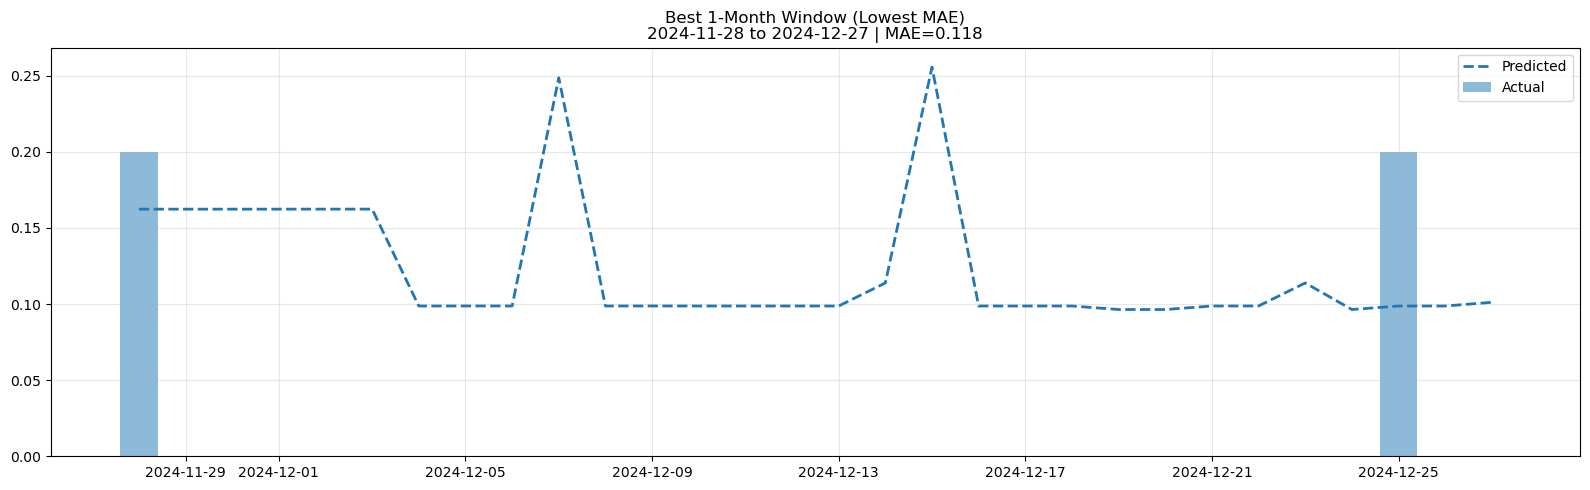

In [54]:
month_start = best_month_mae['start']
month_end = best_month_mae['end']
month_data = eval_df.loc[month_start:month_end]

plt.figure(figsize=(16,5))
plt.bar(month_data.index, month_data['actual'], alpha=0.5, label='Actual')
plt.plot(month_data.index, month_data['pred'], '--', linewidth=2, label='Predicted')

plt.title(
    f"Best 1-Month Window (Lowest MAE)\n"
    f"{month_start.date()} to {month_end.date()} | "
    f"MAE={best_month_mae['mae']:.3f}"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

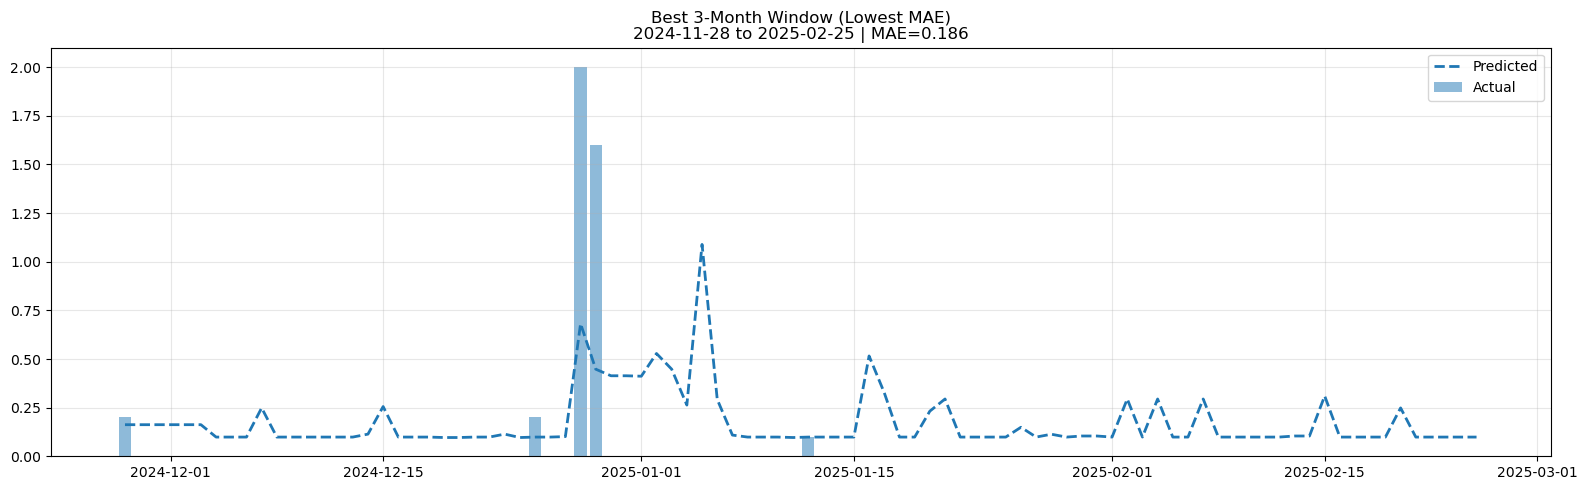

In [55]:
q_start = best_3m_mae['start']
q_end = best_3m_mae['end']
quarter_data = eval_df.loc[q_start:q_end]

plt.figure(figsize=(16,5))
plt.bar(quarter_data.index, quarter_data['actual'], alpha=0.5, label='Actual')
plt.plot(quarter_data.index, quarter_data['pred'], '--', linewidth=2, label='Predicted')

plt.title(
    f"Best 3-Month Window (Lowest MAE)\n"
    f"{q_start.date()} to {q_end.date()} | "
    f"MAE={best_3m_mae['mae']:.3f}"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

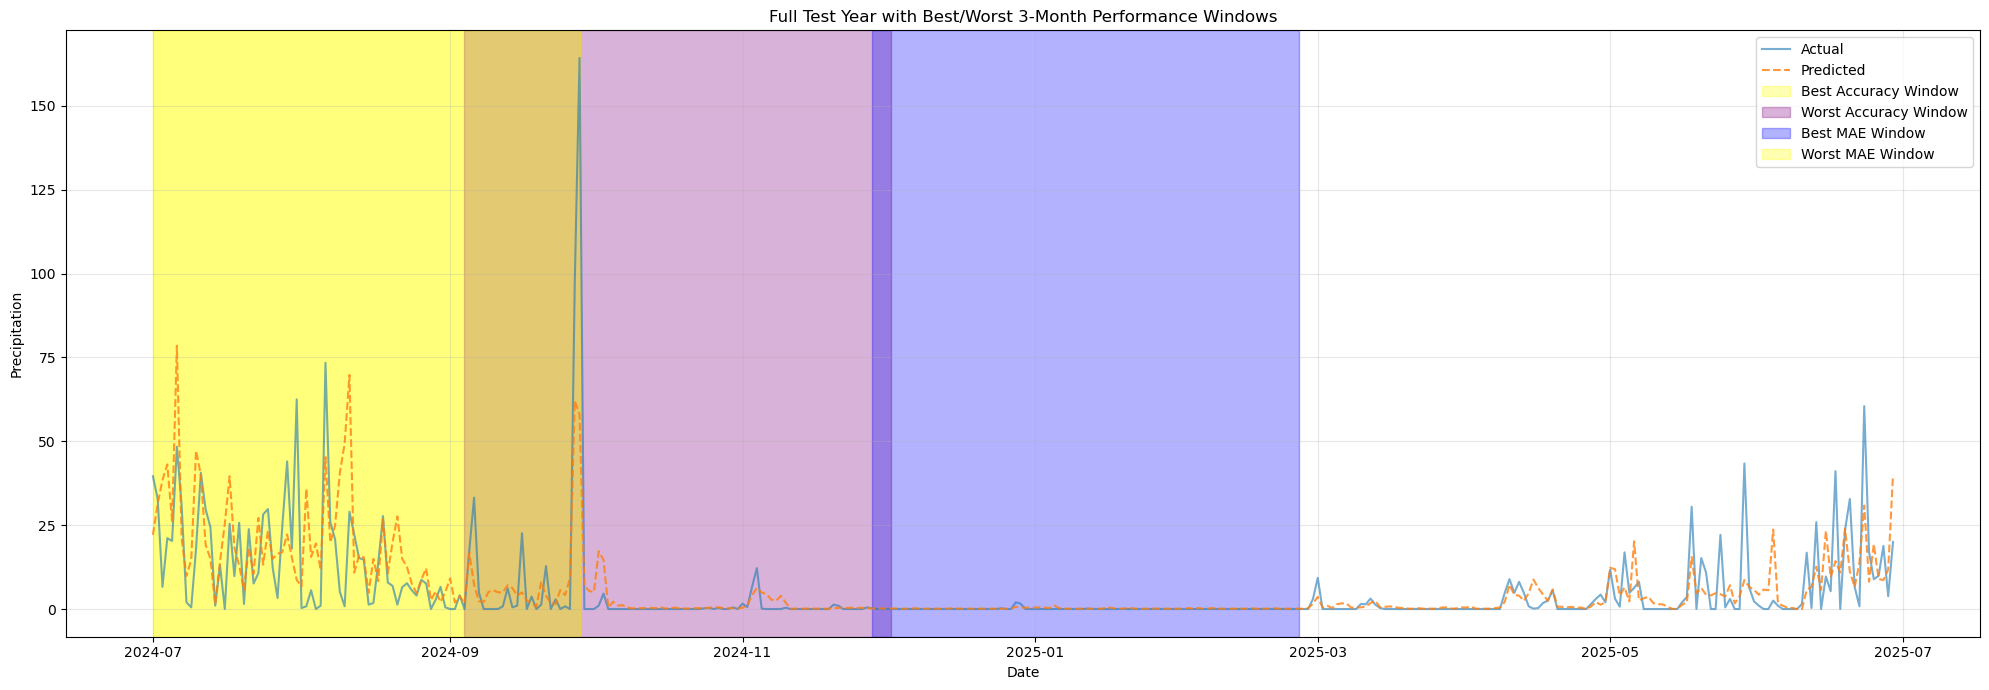

In [67]:
worst_3m_acc = quarter_results.loc[quarter_results['accuracy'].idxmin()]
worst_3m_mae = quarter_results.loc[quarter_results['mae'].idxmax()]
plt.figure(figsize=(20,7))

plt.plot(eval_df.index, eval_df['actual'],
         label='Actual', alpha=0.6)

plt.plot(eval_df.index, eval_df['pred'],
         '--', label='Predicted', alpha=0.8)

# Best accuracy window (green)
plt.axvspan(
    best_3m_acc['start'],
    best_3m_acc['end'],
    color = 'yellow',
    alpha=0.3,
    label='Best Accuracy Window'
)

# Worst accuracy window (red)
plt.axvspan(
    worst_3m_acc['start'],
    worst_3m_acc['end'],
    color = 'purple',
    alpha=0.3,
    label='Worst Accuracy Window'
)

# Best MAE window (blue)
plt.axvspan(
    best_3m_mae['start'],
    best_3m_mae['end'],
    color ='blue',
    alpha=0.30,
    label='Best MAE Window'
)
# Worst MAE window (orange)
plt.axvspan(
    worst_3m_mae['start'],
    worst_3m_mae['end'],
    color = 'yellow',
    alpha=0.30,
    label='Worst MAE Window'
)


plt.title("Full Test Year with Best/Worst 3-Month Performance Windows")
plt.xlabel("Date")
plt.ylabel("Precipitation")
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Testing_Data.jpg", dpi=1000, bbox_inches='tight')
plt.show()


In [ ]:
import matplotlib.pyplot as plt

def plot_highlighted_window(eval_df, window_info, title):
    plt.figure(figsize=(20, 6))

    # Full year graph
    plt.plot(
        eval_df.index,
        eval_df['actual'],
        label='Actual Precipitation',
        linewidth=1,
        alpha=0.7
    )

    plt.plot(
        eval_df.index,
        eval_df['pred'],
        label='Predicted Precipitation',
        linestyle='--',
        linewidth=1,
        alpha=0.8
    )

    # Highlight selected window
    plt.axvspan(
        window_info['start'],
        window_info['end'],
        alpha=0.3
    )

    plt.title(
        f"{title}\n"
        f"{window_info['start'].date()} → {window_info['end'].date()}\n"
        f"Accuracy={window_info['accuracy']:.2f}% | MAE={window_info['mae']:.3f}",
        fontsize=14
    )

    plt.xlabel("Date")
    plt.ylabel("Precipitation")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("Image", dpi=1000, bbox_inches='tight')
    plt.show()

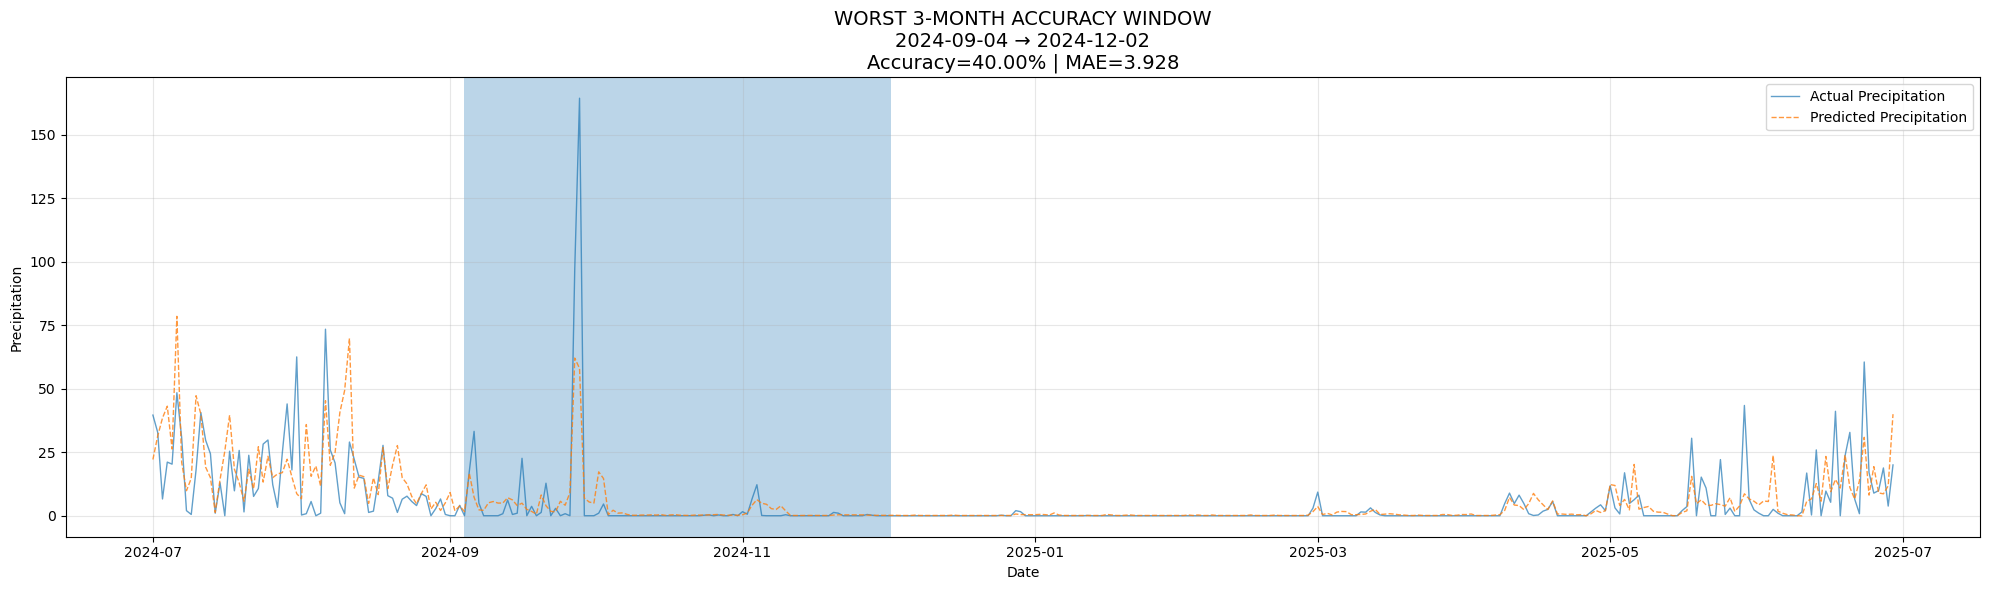

In [ ]:
plot_highlighted_window(
    eval_df,
    worst_3m_acc,
    
    "WORST 3-MONTH ACCURACY WINDOW"
    
)



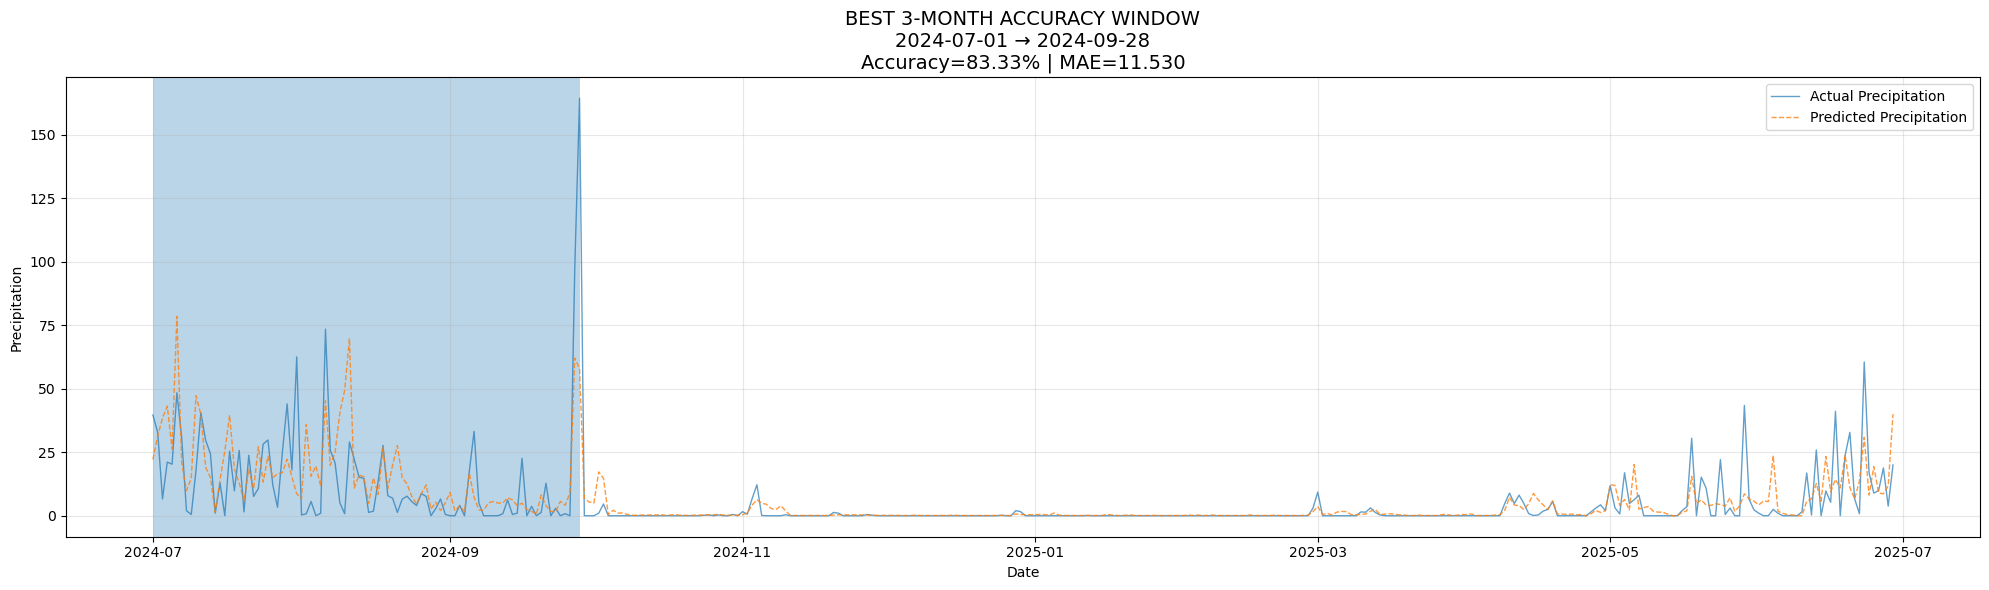

In [ ]:
plot_highlighted_window(
    eval_df,
    best_3m_acc,
    "BEST 3-MONTH ACCURACY WINDOW"
)


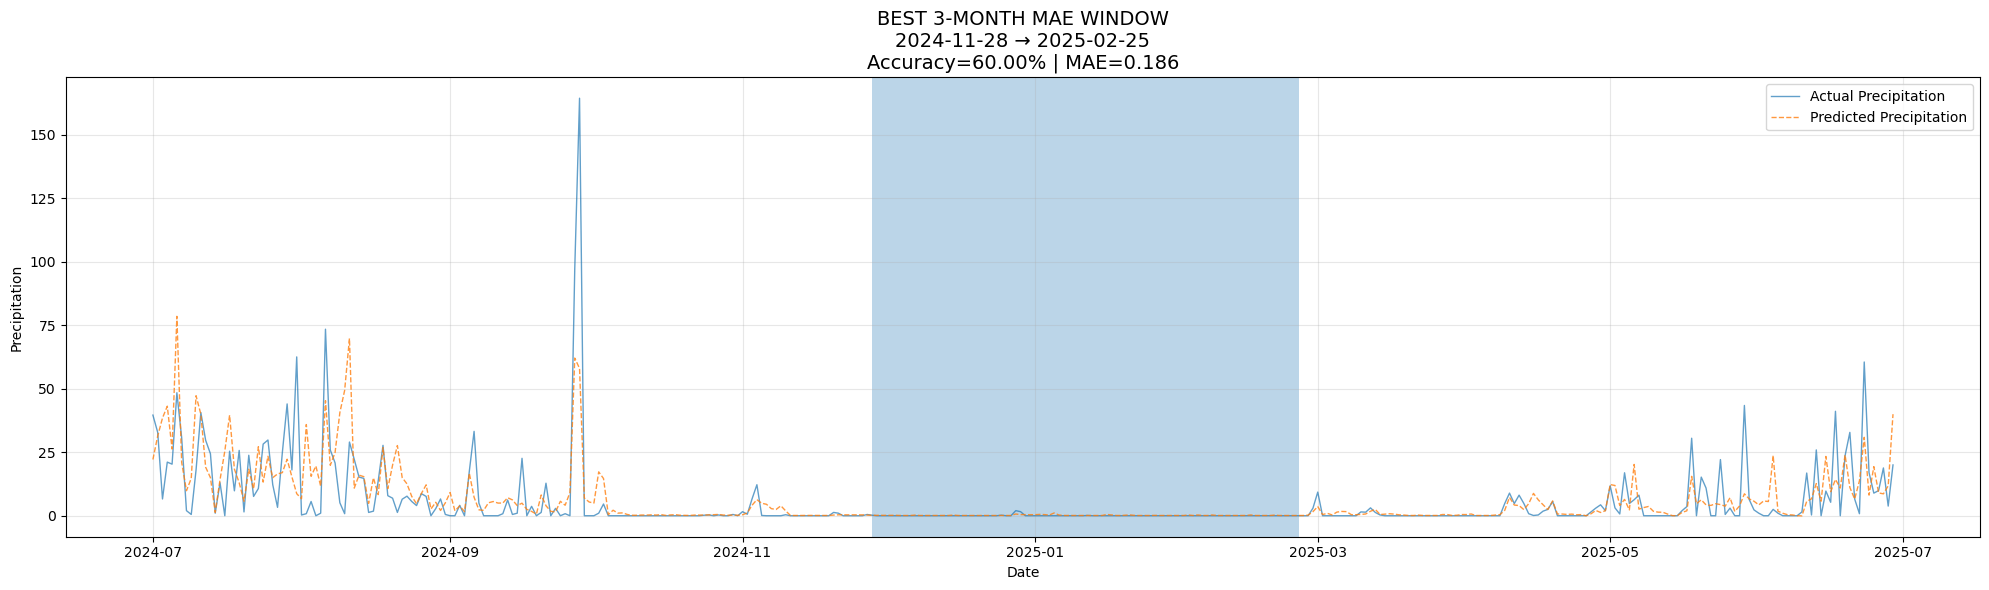

<Figure size 640x480 with 0 Axes>

In [ ]:
plot_highlighted_window(
    eval_df,
    best_3m_mae,
    "BEST 3-MONTH MAE WINDOW"
)
plt.savefig("BEST 3-MONTH MAE WINDOW", dpi=1000, bbox_inches='tight')

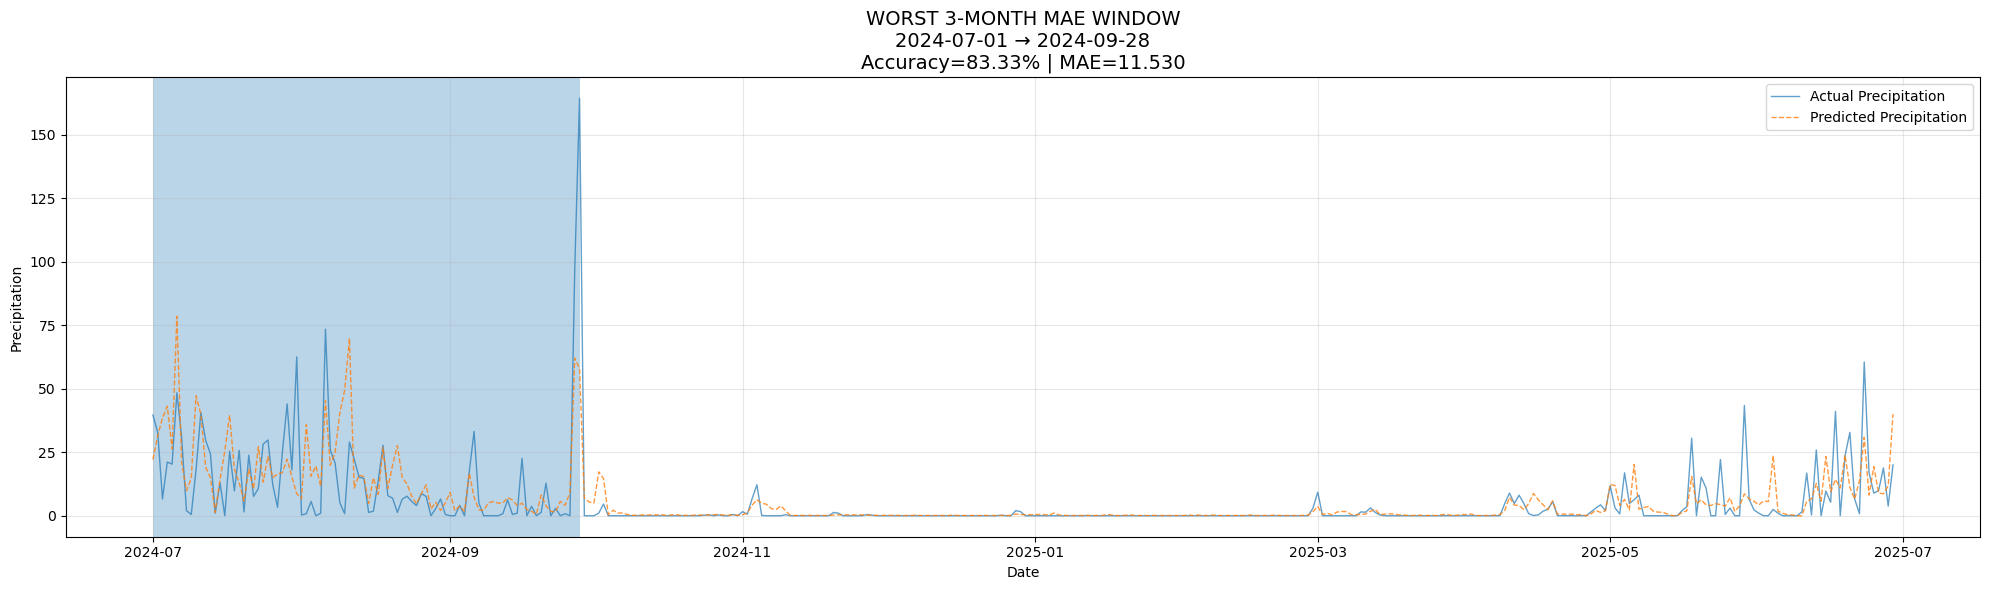

In [ ]:
plot_highlighted_window(
    eval_df,
    worst_3m_mae,
    "WORST 3-MONTH MAE WINDOW"
)
